Fit a multimodal model to a scalar output, with other scalars and a PCA-decomposed time series as auxiliary variables.

In [1]:
import statistics
import scipy.stats as stats
import logging
from pyts.datasets import load_gunpoint
import matplotlib.pyplot as plt
import math
from typing import Optional
import itertools
import random
import copy

import seaborn as sns
import pandas as pd

import torch
import pyro
from pyro.infer import Predictive

from mmbo.mode.timeseries import TSPCA
from mmbo.mode.vae import VAE
from mmbo.examples.testfunc import timeseries_stat, timeseries_full
from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide

In [2]:
logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [3]:
def do_svi(svi, *args, check_interval=1000, max_nonimproved = 3, params = None, **kwargs):
    losses = []
    current_loss = 0
    nonimproved = 0
    best_loss = torch.inf
    if params is None:
        with pyro.get_param_store().scope() as params:
            pass
    best_params = copy.deepcopy(params)
    while nonimproved < max_nonimproved:
        with pyro.get_param_store().scope(params):
            loss = svi.step(*args, **kwargs)
        losses.append(loss)
        if len(losses) >= check_interval and len(losses) % check_interval == 0:
            current_loss = statistics.mean(losses[-check_interval:])
            if current_loss < best_loss:
                best_loss = current_loss
                best_params = copy.deepcopy(params)
                params_updated = True
            else:
                params_updated = False
            current_loss_std = statistics.stdev(losses[-check_interval:])
            reg = stats.linregress(range(check_interval), losses[-check_interval:], alternative = "less")
            if reg.pvalue > 0.1:
                nonimproved += 1
            else:
                nonimproved = 0
            print("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}){} {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, ' +'*params_updated, '*'*nonimproved))
            #logging.info("Step {}, Elbo loss: {:.1f} +/- {:.1f} (slope = {:.3f} +/- {:.3f} loss/k-iter, p-value = {:.3f}) {}".format(len(losses), current_loss, 2 * current_loss_std, 1000*reg.slope, 1000*2*reg.stderr, reg.pvalue, '*'*nonimproved))
    return best_params, losses

In [4]:
# A batched function to calculate the sample covariance
# X is a tensor with shape (*batch_dims, p, n) and the function
# returns a tensor with shape (*batch_dims, p, p) where each p-by-p
# matrix is the sample covariance matrix of the n observations of p variables
# at the corresponding index. Uses the bessel correction
def batch_cov(X: torch.Tensor) -> torch.Tensor:
    n = X.shape[-1]
    mean = X.mean(dim = -1).unsqueeze(-1)
    resids = X - mean
    # permute the dimensions of residuals so matrix multiplication in the
    # covariance formula works
    resids = resids.transpose(-2, -1)
    return (resids.unsqueeze(-1) @ resids.unsqueeze(-2)).sum(dim = -3) / (n - 1)

In [5]:
method = "svi"
#method = "mcmc"

hidden_widths = [256, 256]
pca_var = 0.95

## Generate train and test data

Test data will be both in-sample and out-of-sample to varying degrees.

First, the X-values. X_train = a limited set of training points, X_train_full = a larger set of points at which auxiliary information can be observed, X_test = a larger set of points at which to test

In [6]:
X_vals = [-1.5, -1.0, -0.5, 0.5, 1.0, 1.5]
#X_vals = [-1.5, -0.5, 0.5, 1.5]
amp_log = math.log(0.25)
n_train = len(X_vals) ** 3
X_train = torch.zeros((n_train, 4))
noise = 0.05
res = 200

for i, xi in enumerate(itertools.product(X_vals, X_vals, X_vals)):
    X_train[i,0] = xi[0]
    X_train[i,1] = xi[1]
    X_train[i,2] = amp_log
    X_train[i,3] = xi[2]

In [7]:
X_vals_test = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
n_test = len(X_vals_test) ** 3
X_test = torch.zeros((n_test, 4))
noise_test = 0.05
test_type = [None] * n_test

for i, xi in enumerate(itertools.product(X_vals_test, X_vals_test, X_vals_test)):
    X_test[i,0] = xi[0]
    X_test[i,1] = xi[1]
    X_test[i,2] = amp_log
    X_test[i,3] = xi[2]
    if (xi[0] in X_vals) and (xi[1] in X_vals) and (xi[2] in X_vals):
        test_type[i] = "in_sample"
    elif (X_test[i].abs() > max([abs(i) for i in X_vals])).any():
        test_type[i] = "out_hull"
    else:
        test_type[i] = "in_hull"

in_sample = [i for i in range(n_test) if test_type[i] == "in_sample"]
in_hull = [i for i in range(n_test) if test_type[i] == "in_hull"]
out_hull = [i for i in range(n_test) if test_type[i] == "out_hull"] 


In [8]:
X_vals_full = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
amp_log = math.log(0.25)
n_train_full = len(X_vals_full) ** 3
X_train_full = torch.zeros((n_train_full, 4))
noise = 0.05
modes = ["total_dist", "max_loc", "avg_slope"]

for i, xi in enumerate(itertools.product(X_vals_full, X_vals_full, X_vals_full)):
    X_train_full[i,0] = xi[0]
    X_train_full[i,1] = xi[1]
    X_train_full[i,2] = amp_log
    X_train_full[i,3] = xi[2]


Now Y values of each modality at each set of X points

In [9]:
## Time series

Y_train_ts = timeseries_full(X_train, noise = noise, res = res).unsqueeze(-2)
Y_train_full_ts = timeseries_full(X_train_full, noise = noise, res = res).unsqueeze(-2)
Y_test_ts = timeseries_full(X_test, noise = noise, res = res).unsqueeze(-2)

Y_pca = TSPCA(Y_train_full_ts, n_components = pca_var)

Y_train_ts_pca = Y_pca.encode(Y_train_ts)
Y_train_full_ts_pca = Y_pca.encode(Y_train_full_ts)
Y_test_ts_pca = Y_pca.encode(Y_test_ts)

## Scalar variables

Y_train_sc = torch.cat([timeseries_stat(X_train, m).unsqueeze(-1) for m in modes], dim=-1)
Y_train_full_sc = torch.cat([timeseries_stat(X_train_full, m).unsqueeze(-1) for m in modes], dim=-1)
Y_test_sc = torch.cat([timeseries_stat(X_test, m).unsqueeze(-1) for m in modes], dim=-1)

## Visualize train data

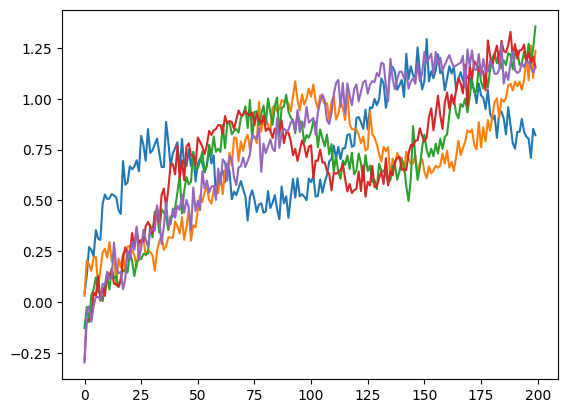

In [10]:
plt.plot(Y_train_ts.squeeze(-2)[50:55].mT)

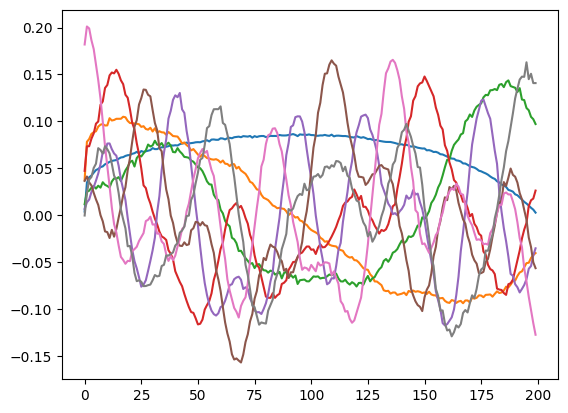

In [11]:
Y_train_ts_pca.shape
Y_pca._pca.components_
plt.plot(Y_pca._pca.components_.mT)

## Visualize test data

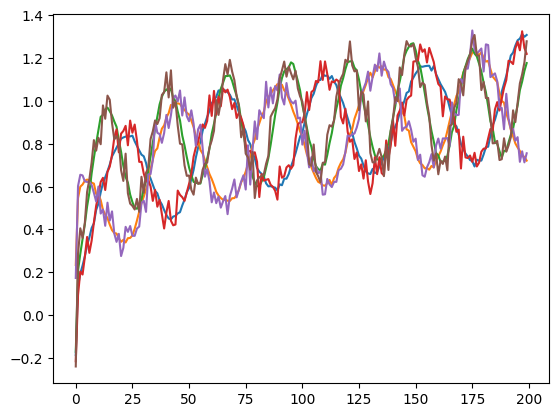

In [12]:
testidx = [in_sample[0], in_hull[0], out_hull[0]]

Y_test_decoded = Y_pca.decode(Y_test_ts_pca)
plt.plot(Y_test_decoded[testidx].squeeze(-2).mT)
plt.plot(Y_test_ts[testidx].squeeze(-2).mT)

In [13]:
# Variance explained in test data
1.0 - (Y_test_ts - Y_test_decoded).var() / Y_test_ts.var()

tensor(0.9692)

## Build and train unimodal model

In [14]:
#adam = pyro.optim.Adam({"lr": 0.001})
adam_seq = [pyro.optim.Adam({"lr": x}) for x in [0.001]]
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

In [15]:
model = RegBNN.from_data(X_train, Y_train_sc[:,0].unsqueeze(-1), hidden_widths = hidden_widths)
guide = RegBNNGuide(model)

#svi = pyro.infer.SVI(model, guide, adam, elbo)
hmc = pyro.infer.NUTS(model.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 48005.7 +/- 29465.0 (slope = -50554.932 +/- 430.135 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 16264.8 +/- 10137.4 (slope = -17377.861 +/- 155.114 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 5461.6 +/- 3424.3 (slope = -5866.492 +/- 53.998 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 1816.8 +/- 1155.7 (slope = -1976.207 +/- 19.776 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 575.1 +/- 405.4 (slope = -690.444 +/- 7.978 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 134.7 +/- 147.9 (slope = -244.355 +/- 4.842 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: -20.4 +/- 60.9 (slope = -84.775 +/- 3.973 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: -76.2 +/- 37.5 (slope = -33.025 +/- 3.539 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: -99.6 +/- 31.4 (slope = -14.598 +/- 3.313 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: -110.9 +/- 29.9 (slope = -8.773 +/- 3.231 loss/k-iter, p-value = 0.0

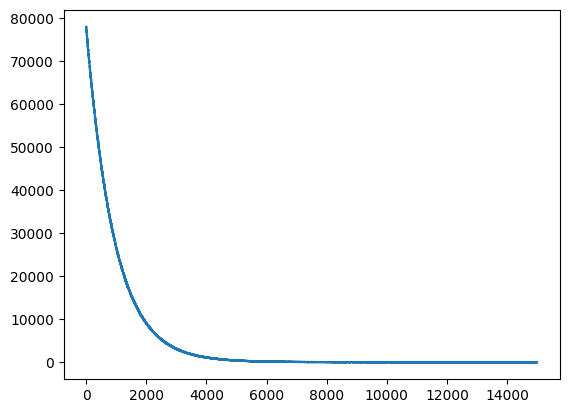

In [16]:
if method == "mcmc":
    mcmc = pyro.infer.MCMC(hmc, num_samples = 100, warmup_steps = 100)
    mcmc.run(X_pred = X_test)
    pred = Predictive(model, mcmc.get_samples())
    Y_pred = pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params = None
    losses = []
    for adam in adam_seq:
        svi = pyro.infer.SVI(model, guide, adam, elbo)
        params, new_losses = do_svi(svi, params = params)
        losses += new_losses
    plt.plot(losses)
    guide.eval()
    with param_store.scope(params):
        pred = Predictive(model, guide = guide, num_samples = 100)
        Y_pred = pred.get_samples(X_pred = X_test)['mu_pred']

In [17]:
def plot_predictions_ts(Y_test, Y_pred, series_idx):
    Y_true = Y_test[series_idx].squeeze()
    Y_pred = Y_pred[:,series_idx].squeeze(-2).mT
    # Set up figure/axes
    fig, ax = plt.subplots(figsize=(10, 5))
    ylims = [1.5*Y_pred.min().detach() - 0.5*Y_pred.max().detach(), 1.5*Y_pred.max().detach() - 0.5*Y_pred.min().detach()]
    plt.ylim(ylims)
    # Plot true function
    ax.plot(Y_true, 'k-', linewidth=3, label="true function", zorder = 20)
    # Plot data points
    ax.plot(Y_pred, 'b-', linewidth=1, alpha=0.5, label="estimates", zorder = 15)

def plot_predictions_pairs(Y_test, Y_pred, idx):
    Y_true = Y_test[idx]
    Y_pred = Y_pred[:,idx]
    colnames = [f"Y_{n}" for n in range(Y_pred.shape[-1])]
    data = pd.DataFrame(Y_pred, columns=colnames)
    data["Type"] = "Pred"
    data_true = pd.DataFrame(Y_true.unsqueeze(0), columns=colnames)
    data_true["Type"] = "True"
    g = sns.pairplot(pd.concat([data, data_true]), hue="Type", height = 1.5, diag_kind="hist")

In [18]:
random.shuffle(in_sample)
random.shuffle(in_hull)
random.shuffle(out_hull)

idx = 0

### In-sample

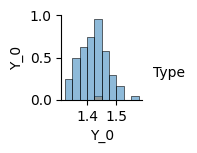

In [19]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred, in_sample[idx])

### Out of sample but within the convex hull

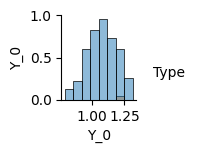

In [20]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred, in_hull[idx])

### Out of the convex hull

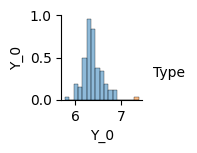

In [21]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred, out_hull[idx])

## Build and train a multimodal model

Set up multimodal training data:
* With the original X_train
* With an expanded X_train that significantly grows the convex hull of 

In [22]:
model_mm = LayeredRegBNN.from_data(X_train, Y_train_sc[:,0].unsqueeze(-1), [X_train_full, X_train_full], [Y_train_full_ts_pca, Y_train_full_sc[:,1:]], hidden_widths = hidden_widths)
guide_mm = LayeredRegBNNGuide(model_mm)

#svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
hmc_mm = pyro.infer.NUTS(model_mm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 105909.9 +/- 57345.6 (slope = -98396.809 +/- 834.580 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 43424.9 +/- 20719.5 (slope = -35580.972 +/- 287.342 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 19894.8 +/- 8328.8 (slope = -14307.450 +/- 113.189 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 10122.7 +/- 3554.3 (slope = -6001.167 +/- 86.049 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 8910.9 +/- 3895.4 (slope = 30.554 +/- 426.934 loss/k-iter, p-value = 0.557) + *
Step 6000, Elbo loss: 8587.3 +/- 5306.0 (slope = 193.840 +/- 581.410 loss/k-iter, p-value = 0.747) + **
Step 7000, Elbo loss: 8422.0 +/- 1198.4 (slope = -138.250 +/- 131.047 loss/k-iter, p-value = 0.018) + 
Step 8000, Elbo loss: 8305.7 +/- 1412.8 (slope = -200.630 +/- 154.318 loss/k-iter, p-value = 0.005) + 
Step 9000, Elbo loss: 8204.5 +/- 1440.0 (slope = -130.532 +/- 157.607 loss/k-iter, p-value = 0.049) + 
Step 10000, Elbo loss: 8109.6 +/- 1411.7 (slope = -90.519 +/

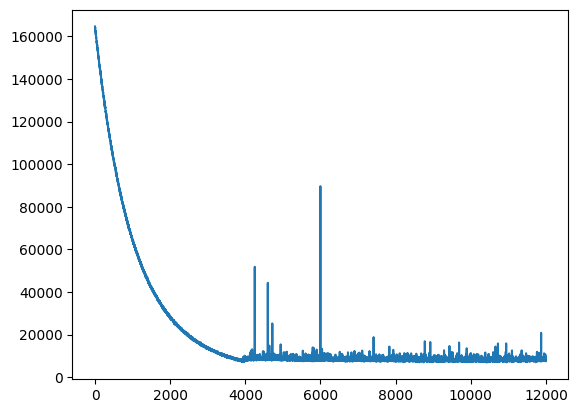

In [23]:
if method == "mcmc":
    mcmc_mm = pyro.infer.MCMC(hmc_mm, num_samples = 100, warmup_steps = 100)
    mcmc_mm.run(X_pred = X_test)
    pred_mm = Predictive(model_mm, mcmc_mm.get_samples())
    Y_pred_mm = pred_mm.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params_mm = None
    losses_mm = []
    for adam in adam_seq:
        svi_mm = pyro.infer.SVI(model_mm, guide_mm, adam, elbo)
        params_mm, new_losses = do_svi(svi_mm, params = params_mm)
        losses_mm += new_losses
    plt.plot(losses_mm)
    guide_mm.eval()
    with param_store.scope(params_mm):
        pred_mm = Predictive(model_mm, guide = guide_mm, num_samples = 100)
        Y_pred_mm = pred_mm.get_samples(X_pred = X_test)['mu_pred']

### In-sample

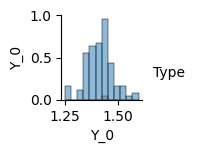

In [24]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_mm, in_sample[idx])

### Out of sample but within the convex hull

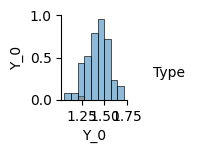

In [25]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_mm, in_hull[idx])

### Out of the convex hull

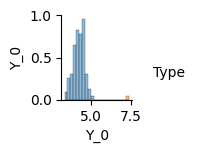

In [26]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_mm, out_hull[idx])

## Compare unimodal and multimodal models on the whole

Compare bias and uncertainty for in-sample, in-hull and out of hull test points

### Bias

Difference between true point and mean of posterior predictions

Text(0, 0.5, 'Multimodal')

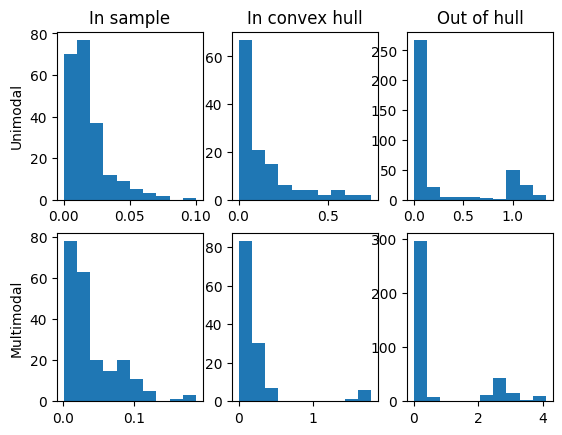

In [27]:
Y_bias = (Y_pred.mean(dim=0) - Y_test_sc[:,0].unsqueeze(-1)).pow(2).sum(dim=-1).sqrt() # Combine bias in Euclidian distance fashion
Y_bias_mm = (Y_pred_mm.mean(dim=0) - Y_test_sc[:,0].unsqueeze(-1)).pow(2).sum(dim=-1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_bias[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_bias[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_bias_mm[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_bias_mm[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_bias_mm[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

Text(0, 0.5, 'Multimodal')

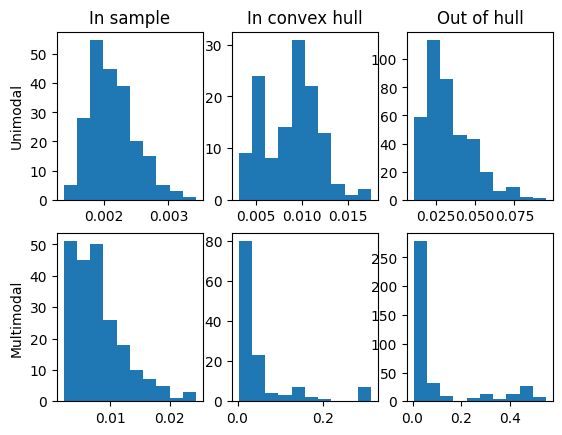

In [28]:
Y_var = Y_pred.var(dim=0).sum(dim=-1) # Add marginal variances
Y_var_mm = Y_pred_mm.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_mm[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_mm[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_mm[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")

## "Fake" multimodal model

Skip the auxiliary surrogate model and just pass the true aux variables in as training features.

In [29]:
X_train_fakemm = torch.cat([X_train, Y_train_ts_pca, Y_train_sc[:,1:]], dim=-1)
X_test_fakemm = torch.cat([X_test, Y_test_ts_pca, Y_test_sc[:,1:]], dim=-1)

In [30]:
model_fakemm = RegBNN.from_data(X_train_fakemm, Y_train_sc[:,0].unsqueeze(-1), hidden_widths = hidden_widths)
guide_fakemm = RegBNNGuide(model_fakemm)

#svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
hmc_fakemm = pyro.infer.NUTS(model_fakemm.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 49336.5 +/- 30525.3 (slope = -52369.166 +/- 447.895 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 16484.1 +/- 10456.2 (slope = -17919.129 +/- 162.311 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 5416.0 +/- 3473.6 (slope = -5949.046 +/- 55.548 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 1746.4 +/- 1146.8 (slope = -1961.243 +/- 19.487 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 536.0 +/- 382.2 (slope = -647.840 +/- 8.534 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 137.2 +/- 129.1 (slope = -209.911 +/- 4.871 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 6.2 +/- 54.3 (slope = -69.019 +/- 4.039 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: -37.2 +/- 38.6 (slope = -29.137 +/- 3.805 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: -54.5 +/- 33.9 (slope = -12.629 +/- 3.627 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: -62.0 +/- 32.9 (slope = -6.514 +/- 3.582 loss/k-iter, p-value = 0.000)

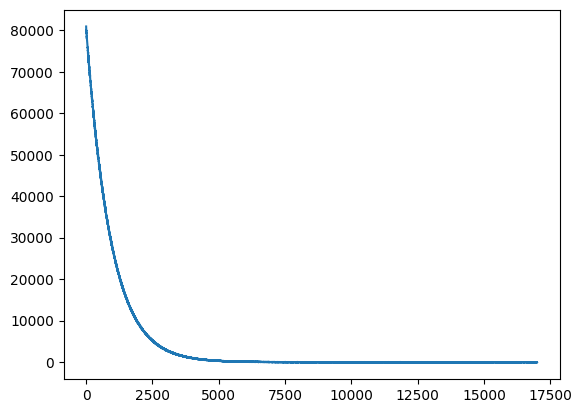

In [31]:
if method == "mcmc":
    mcmc_fakemm = pyro.infer.MCMC(hmc_fakemm, num_samples = 100, warmup_steps = 100)
    mcmc_fakemm.run(X_pred = X_test_fakemm)
    pred_fakemm = Predictive(model_fakemm, mcmc_fakemm.get_samples())
    Y_pred_fakemm = pred.get_samples(X_pred = X_test_fakemm)['mu_pred']
elif method == "svi":
    params_fakemm = None
    losses_fakemm = []
    for adam in adam_seq:
        svi_fakemm = pyro.infer.SVI(model_fakemm, guide_fakemm, adam, elbo)
        params_fakemm, new_losses = do_svi(svi_fakemm, params = params_fakemm)
        losses_fakemm += new_losses
    plt.plot(losses_fakemm)
    guide_fakemm.eval()
    with param_store.scope(params_fakemm):
        pred_fakemm = Predictive(model_fakemm, guide = guide_fakemm, num_samples = 100)
        Y_pred_fakemm = pred_fakemm.get_samples(X_pred = X_test_fakemm)['mu_pred']

### In sample

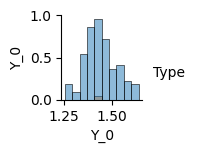

In [32]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_fakemm, in_sample[idx])

### Out of sample but in convex hull

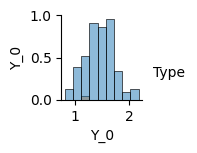

In [33]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_fakemm, in_hull[idx])

### Out of convex hull

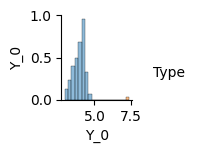

In [34]:
plot_predictions_pairs(Y_test_sc[:,0].unsqueeze(-1), Y_pred_fakemm, out_hull[idx])

### Evaluate Fake multimodal model vs unimodal model overall

#### Bias

Text(0, 0.5, "'Fake' Multimodal")

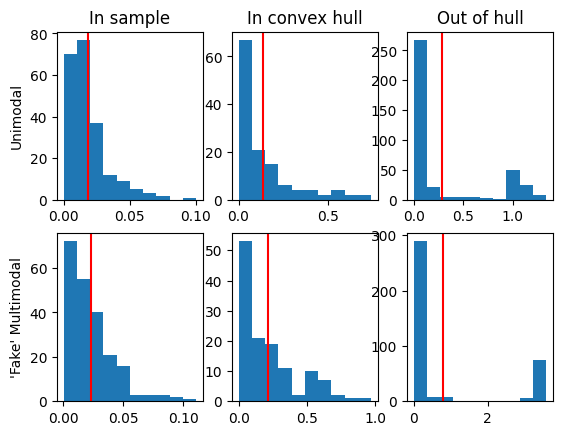

In [35]:
Y_bias_fakemm = (Y_pred_fakemm.mean(dim=0) - Y_test_sc[:,0].unsqueeze(-1)).pow(2).sum(dim = -1).sqrt()

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_bias[in_sample])
axs[0,0].axvline(Y_bias[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_bias[in_hull])
axs[0,1].axvline(Y_bias[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_bias[out_hull])
axs[0,2].axvline(Y_bias[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_bias_fakemm[in_sample])
axs[1,0].axvline(Y_bias_fakemm[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_bias_fakemm[in_hull])
axs[1,1].axvline(Y_bias_fakemm[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_bias_fakemm[out_hull])
axs[1,2].axvline(Y_bias_fakemm[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Variance

Text(0, 0.5, "'Fake' Multimodal")

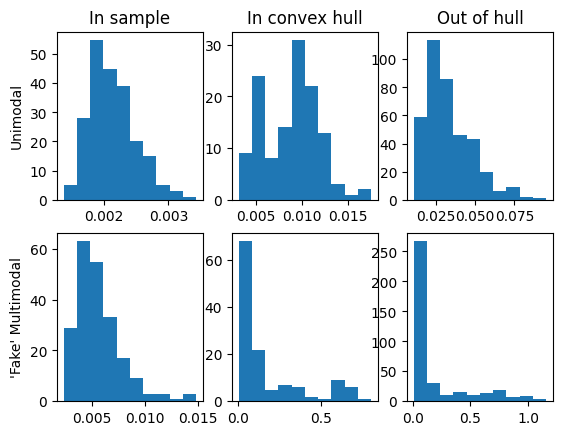

In [36]:

Y_var_fakemm = Y_pred_fakemm.var(dim=0).sum(dim=-1)

fig, axs = plt.subplots(2,3)
# Unimodal, in sample
axs[0,0].hist(Y_var[in_sample])
# Unimodal, in hull
axs[0,1].hist(Y_var[in_hull])
# Unimodal, out hull
axs[0,2].hist(Y_var[out_hull])
# Multimodal, in sample
axs[1,0].hist(Y_var_fakemm[in_sample])
# Multimodal, in hull
axs[1,1].hist(Y_var_fakemm[in_hull])
# Multimodal, out hull
axs[1,2].hist(Y_var_fakemm[out_hull])

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("'Fake' Multimodal")

#### Normalized Error

Text(0, 0.5, "'Fake' Multimodal")

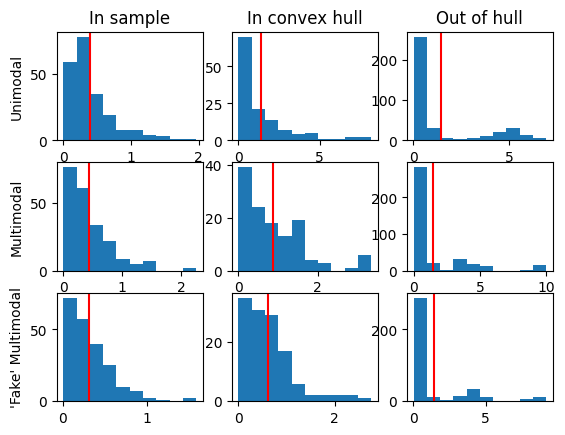

In [37]:
def mv_zscore(Y: torch.Tensor, mean: torch.Tensor, cov: torch.Tensor) -> torch.Tensor:
    """
    Y.shape == (*batch_dims, p)
    mean.shape == (*batch_dims, p)
    cov.shape == (*batch_dims, p, p)
    """
    p = Y.shape[-1]
    return (((Y - mean).unsqueeze(-2) @ cov.inverse() @ (Y - mean).unsqueeze(-1)).squeeze(-1).squeeze(-1) / p).sqrt()

#Y_zscore_pca = Y_bias_pca / Y_var_pca.sqrt()
#Y_zscore_fakemm_pca = Y_bias_fakemm_pca / Y_var_fakemm_pca.sqrt()
Y_mean = Y_pred.mean(dim=0)
Y_mean_mm = Y_pred_mm.mean(dim=0)
Y_mean_fakemm = Y_pred_fakemm.mean(dim=0)
Y_cov = batch_cov(Y_pred.permute(1,2,0))
Y_cov_mm = batch_cov(Y_pred_mm.permute(1,2,0))
Y_cov_fakemm = batch_cov(Y_pred_fakemm.permute(1,2,0))
Y_zscore = mv_zscore(Y_test_sc[:,0].unsqueeze(-1), Y_mean, Y_cov)
Y_zscore_mm = mv_zscore(Y_test_sc[:,0].unsqueeze(-1), Y_mean_mm, Y_cov_mm)
Y_zscore_fakemm = mv_zscore(Y_test_sc[:,0].unsqueeze(-1), Y_mean_fakemm, Y_cov_fakemm)


fig, axs = plt.subplots(3,3)
# Unimodal, in sample
axs[0,0].hist(Y_zscore[in_sample])
axs[0,0].axvline(Y_zscore[in_sample].mean(), color="red")
# Unimodal, in hull
axs[0,1].hist(Y_zscore[in_hull])
axs[0,1].axvline(Y_zscore[in_hull].mean(), color="red")
# Unimodal, out hull
axs[0,2].hist(Y_zscore[out_hull])
axs[0,2].axvline(Y_zscore[out_hull].mean(), color="red")
# Multimodal, in sample
axs[1,0].hist(Y_zscore_mm[in_sample])
axs[1,0].axvline(Y_zscore_mm[in_sample].mean(), color="red")
# Multimodal, in hull
axs[1,1].hist(Y_zscore_mm[in_hull])
axs[1,1].axvline(Y_zscore_mm[in_hull].mean(), color="red")
# Multimodal, out hull
axs[1,2].hist(Y_zscore_mm[out_hull])
axs[1,2].axvline(Y_zscore_mm[out_hull].mean(), color="red")
# 'Fake' Multimodal, in sample
axs[2,0].hist(Y_zscore_fakemm[in_sample])
axs[2,0].axvline(Y_zscore_fakemm[in_sample].mean(), color="red")
# 'Fake' Multimodal, in hull
axs[2,1].hist(Y_zscore_fakemm[in_hull])
axs[2,1].axvline(Y_zscore_fakemm[in_hull].mean(), color="red")
# 'Fake' Multimodal, out hull
axs[2,2].hist(Y_zscore_fakemm[out_hull])
axs[2,2].axvline(Y_zscore_fakemm[out_hull].mean(), color="red")

# Titles
axs[0,0].set_title("In sample")
axs[0,1].set_title("In convex hull")
axs[0,2].set_title("Out of hull")
axs[0,0].set_ylabel("Unimodal")
axs[1,0].set_ylabel("Multimodal")
axs[2,0].set_ylabel("'Fake' Multimodal")

## Joint multimodal model

In [38]:
# Joint x = X_train_full
# first combine them all then replace the missing values in the main modality with nan
Y_train_joint = torch.cat([Y_train_full_sc, Y_train_full_ts_pca], dim = -1)

for i in range(Y_train_joint.shape[0]):
    # If X_train_full[i] is not in X_train, then replance Y_train_joint[i,0] with torch.nan
    if not (X_train_full[i] == X_train).all(dim = -1).any():
        Y_train_joint[i,0] = torch.nan

In [39]:
model_joint = RegBNN.from_data(X_train_full, Y_train_joint, hidden_widths = hidden_widths)
guide_joint = RegBNNGuide(model_joint)

hmc_joint = pyro.infer.NUTS(model_joint.no_missing())

/home/itaylor/projects/mmbo/.venv/lib/python3.11/site-packages/torch/distributions/wishart.py:271: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


Step 1000, Elbo loss: 57704.8 +/- 25415.8 (slope = -42828.273 +/- 638.436 loss/k-iter, p-value = 0.000) + 
Step 2000, Elbo loss: 40263.3 +/- 2265.4 (slope = -3653.595 +/- 90.245 loss/k-iter, p-value = 0.000) + 
Step 3000, Elbo loss: 38467.3 +/- 759.5 (slope = -878.984 +/- 61.907 loss/k-iter, p-value = 0.000) + 
Step 4000, Elbo loss: 37807.1 +/- 656.9 (slope = -578.407 +/- 61.993 loss/k-iter, p-value = 0.000) + 
Step 5000, Elbo loss: 37315.6 +/- 607.9 (slope = -386.867 +/- 61.963 loss/k-iter, p-value = 0.000) + 
Step 6000, Elbo loss: 36961.7 +/- 600.6 (slope = -378.355 +/- 61.311 loss/k-iter, p-value = 0.000) + 
Step 7000, Elbo loss: 36657.7 +/- 565.5 (slope = -307.834 +/- 58.834 loss/k-iter, p-value = 0.000) + 
Step 8000, Elbo loss: 36304.5 +/- 608.0 (slope = -368.366 +/- 62.428 loss/k-iter, p-value = 0.000) + 
Step 9000, Elbo loss: 35861.6 +/- 599.3 (slope = -403.337 +/- 60.516 loss/k-iter, p-value = 0.000) + 
Step 10000, Elbo loss: 35488.6 +/- 612.5 (slope = -423.717 +/- 61.542 loss/

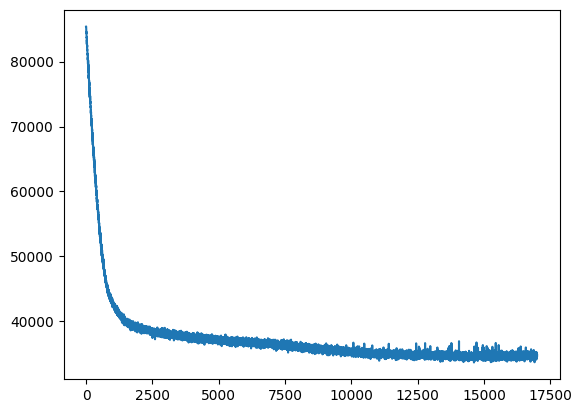

In [40]:
if method == "mcmc":
    mcmc_joint = pyro.infer.MCMC(hmc_joint, num_samples = 100, warmup_steps = 100)
    mcmc_joint.run(X_pred = X_test)
    pred_joint= Predictive(model_joint, mcmc_joint.get_samples())
    Y_pred_joint= pred.get_samples(X_pred = X_test)['mu_pred']
elif method == "svi":
    params_joint = None
    losses_joint = []
    for adam in adam_seq:
        svi_joint = pyro.infer.SVI(model_joint, guide_joint, adam, elbo)
        params_joint, new_losses = do_svi(svi_joint, params = params_joint)
        losses_joint += new_losses
    plt.plot(losses_joint)
    guide_joint.eval()
    with param_store.scope(params_joint):
        pred_joint = Predictive(model_joint, guide = guide_joint, num_samples = 100)
        Y_pred_joint = pred_joint.get_samples(X_pred = X_test)['mu_pred']